# Embeddingi fastText + MLP (spam w klasie pozytywnej)

Wariant `spam_1`: ogólny klasyfikator niechcianych wiadomości, więc phishing i spam należą do klasy pozytywnej (etykieta `label_spam_1`).

- **Cechy:** te same co w `fasttext_xgb_spam_1`: 300-wymiarowy embedding dokumentu z modelu `cc.en.300.bin`, czyli średnia
  znormalizowanych wektorów słów (`get_sentence_vector`). Embeddingi liczone są raz dla wszystkich wiadomości, bo model fastText
  nie widzi etykiet.
- **Standaryzacja:** każdy wymiar jest standaryzowany (`StandardScaler`) na części uczącej foldu, a w modelu końcowym na całym
  zbiorze treningowym. Bez niej sieć uczy się wolno, bo składowe wektorów fastText mają bardzo małą skalę.
- **Model:** sieć MLP w PyTorch (warstwy Linear, ReLU i Dropout), optymalizator AdamW, entropia krzyżowa, batch 256.
- **Dobór hiperparametrów:** grid z k-fold CV na zbiorze treningowym. Foldy są rozłączne względem klastrów, a kryterium to AUCPR
  ważone odwrotnością rozmiaru klastra. Liczba epok jest dobierana wczesnym zatrzymaniem.
- **Podział:** 60% train, 30% val, 10% test na poziomie klastrów, taki sam we wszystkich eksperymentach.
- **Próg:** na zbiorze walidacyjnym, największy recall przy FPR ważonym klastrami nie większym niż 1%.
- **Ocena:** zbiór testowy ID i cały korpus OOD, a także każde źródło osobno.

In [ ]:
import itertools
import sys
import time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import (
    ID_SOURCES, OOD_SOURCES, TARGET_FPR, cluster_folds, cluster_weights, corpus_metrics, fasttext_embeddings, load_corpora,
    plot_confusion_matrices, plot_curves, threshold_at_fpr,
)
from mlp_utils import DEVICE, n_parameters, predict, train_mlp

EXPERIMENT = "fasttext_mlp_spam_1"
LABEL = "label_spam_1"
RESULTS = ROOT / "results" / EXPERIMENT
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100, "display.float_format", "{:.4f}".format)

N_FOLDS = 3
HIDDEN_LAYERS = ((256,), (512,), (512, 256))
DROPOUTS = (0.2, 0.5)
LEARNING_RATES = (1e-3, 3e-4)
WEIGHT_DECAYS = (1e-4, 1e-2)
# Epoka na 300-wymiarowych wektorach trwa ułamek sekundy, a przy kroku 3e-4 najlepsza epoka bywa powyżej 20,
# dlatego limit jest wyższy niż w TF-IDF + MLP. Cierpliwość jest taka sama.
MAX_EPOCHS = 100
PATIENCE = 3
SEED = 42
print("Urządzenie:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Urządzenie: cuda NVIDIA GeForce RTX 2080


## Dane i podział

In [2]:
in_domain, out_of_domain = load_corpora()
train, val, test = (in_domain[in_domain.split == name] for name in ("train", "val", "test"))
assert not set(train.cluster) & set(val.cluster) and not set(train.cluster) & set(test.cluster) and not set(val.cluster) & set(test.cluster)
print({name: len(frame) for name, frame in (("train", train), ("val", val), ("test", test), ("ood", out_of_domain))})
start = time.perf_counter()
id_embeddings, ood_embeddings = fasttext_embeddings(in_domain.text, out_of_domain.text)
embedding_seconds = time.perf_counter() - start
position = pd.Series(np.arange(len(in_domain)), index=in_domain.index)


def embed(frame):
    return ood_embeddings if frame is out_of_domain else id_embeddings[position[frame.index].to_numpy()]


print(f"Embeddingi: {id_embeddings.shape} ID, {ood_embeddings.shape} OOD, {embedding_seconds:.0f} s")

{'train': 80679, 'val': 40720, 'test': 13070, 'ood': 6124}


Embeddingi: (134469, 300) ID, (6124, 300) OOD, 56 s


## Grid z k-fold CV

Liczba epok nie jest częścią siatki, tylko jest dobierana wczesnym zatrzymaniem (early stopping). W każdym foldzie po każdej
epoce liczone jest AUCPR ważone klastrami na części holdout, a uczenie kończy się po `PATIENCE` epokach bez poprawy
(najwyżej `MAX_EPOCHS`). Wynik foldu to AUCPR dla najlepszej epoki, a model końcowy dostaje średnią z tych liczb po foldach.

In [3]:
cv_rows = []
cv_start = time.perf_counter()
for fold, (fit_index, holdout_index) in enumerate(cluster_folds(train[LABEL], train.cluster, N_FOLDS, SEED)):
    fit_frame, holdout_frame = train.iloc[fit_index], train.iloc[holdout_index]
    assert not set(fit_frame.cluster) & set(holdout_frame.cluster)
    scaler = StandardScaler().fit(embed(fit_frame))
    fit_features, holdout_features = scaler.transform(embed(fit_frame)), scaler.transform(embed(holdout_frame))
    holdout_labels, holdout_weights = holdout_frame[LABEL].to_numpy(), cluster_weights(holdout_frame.cluster)
    for hidden, dropout, learning_rate, weight_decay in itertools.product(HIDDEN_LAYERS, DROPOUTS, LEARNING_RATES, WEIGHT_DECAYS):
        start = time.perf_counter()
        model, history, n_epochs = train_mlp(
            fit_features, fit_frame[LABEL], hidden, dropout, learning_rate, weight_decay, SEED, MAX_EPOCHS,
            holdout=(holdout_features, holdout_labels, holdout_weights), patience=PATIENCE,
        )
        scores = predict(model, holdout_features)
        cv_rows.append({
            "fold": fold, "hidden": str(hidden), "dropout": dropout, "learning_rate": learning_rate,
            "weight_decay": weight_decay, "n_epochs": n_epochs,
            "aucpr_ważone": average_precision_score(holdout_labels, scores, sample_weight=holdout_weights),
            "aucpr": average_precision_score(holdout_labels, scores),
        })
        print(
            f"fold {fold}, {hidden}, dropout {dropout}, lr {learning_rate}, wd {weight_decay}: "
            f"{n_epochs} epok, AUCPR ważone {max(history):.4f}, {time.perf_counter() - start:.0f} s", flush=True,
        )
        del model
cv_seconds = time.perf_counter() - cv_start

cv_folds = pd.DataFrame(cv_rows)
cv_folds.to_csv(TABLES / "cv_folds.csv", index=False)
GRID_COLUMNS = ["hidden", "dropout", "learning_rate", "weight_decay"]
cv_results = (
    cv_folds.groupby(GRID_COLUMNS)[["aucpr_ważone", "aucpr", "n_epochs"]].agg(["mean", "std"])
    .sort_values(("aucpr_ważone", "mean"), ascending=False)
)
cv_results.columns = [f"{metric}_{statistic}" for metric, statistic in cv_results.columns]
cv_results = cv_results.reset_index()
cv_results.to_csv(TABLES / "cv_results.csv", index=False)
best = cv_results.iloc[0]
print(f"Czas grida: {cv_seconds / 60:.1f} min")
display(cv_results.head(10))

fold 0, (256,), dropout 0.2, lr 0.001, wd 0.0001: 8 epok, AUCPR ważone 0.9858, 3 s


fold 0, (256,), dropout 0.2, lr 0.001, wd 0.01: 16 epok, AUCPR ważone 0.9864, 3 s


fold 0, (256,), dropout 0.2, lr 0.0003, wd 0.0001: 21 epok, AUCPR ważone 0.9870, 4 s


fold 0, (256,), dropout 0.2, lr 0.0003, wd 0.01: 21 epok, AUCPR ważone 0.9870, 4 s


fold 0, (256,), dropout 0.5, lr 0.001, wd 0.0001: 13 epok, AUCPR ważone 0.9860, 3 s


fold 0, (256,), dropout 0.5, lr 0.001, wd 0.01: 13 epok, AUCPR ważone 0.9858, 3 s


... (64 outputs left out)

fold 2, (512, 256), dropout 0.5, lr 0.0003, wd 0.0001: 24 epok, AUCPR ważone 0.9878, 6 s


fold 2, (512, 256), dropout 0.5, lr 0.0003, wd 0.01: 24 epok, AUCPR ważone 0.9878, 6 s


Czas grida: 4.3 min


,hidden,dropout,learning_rate,weight_decay,aucpr_ważone_mean,aucpr_ważone_std,aucpr_mean,aucpr_std,n_epochs_mean,n_epochs_std
0,"(512, 256)",0.5000,0.0010,0.0001,0.9887,0.0008,0.9931,0.0011,18.3333,8.1445
1,"(512, 256)",0.5000,0.0010,0.0100,0.9880,0.0009,0.9928,0.0012,11.6667,5.5076
2,"(512,)",0.2000,0.0003,0.0001,0.9871,0.0009,0.9923,0.0012,19.6667,4.5092
3,"(512,)",0.2000,0.0003,0.0100,0.9871,0.0009,0.9921,0.0015,18.0000,2.6458
4,"(512,)",0.5000,0.0003,0.0100,0.9868,0.0013,0.9915,0.0021,22.6667,3.7859
5,"(512,)",0.5000,0.0003,0.0001,0.9868,0.0013,0.9915,0.0021,22.6667,3.7859
6,"(256,)",0.2000,0.0003,0.0001,0.9867,0.0008,0.9916,0.0017,21.6667,2.0817
7,"(512, 256)",0.5000,0.0003,0.0100,0.9867,0.0010,0.9919,0.0011,15.6667,7.3711
8,"(512, 256)",0.5000,0.0003,0.0001,0.9867,0.0010,0.9921,0.0011,15.6667,7.3711
9,"(256,)",0.2000,0.0003,0.0100,0.9866,0.0008,0.9916,0.0017,21.6667,2.0817


## Uczenie modelu końcowego

Model z najlepszymi hiperparametrami jest uczony na całym zbiorze treningowym.

In [4]:
best_params = {
    "hidden": best.hidden, "dropout": float(best.dropout), "learning_rate": float(best.learning_rate),
    "weight_decay": float(best.weight_decay), "n_epochs": max(1, int(round(best.n_epochs_mean))),
}
start = time.perf_counter()
scaler = StandardScaler().fit(embed(train))
model, _, _ = train_mlp(
    scaler.transform(embed(train)), train[LABEL], tuple(int(size) for size in best_params["hidden"].strip("(),").split(",")),
    best_params["dropout"], best_params["learning_rate"], best_params["weight_decay"], SEED, best_params["n_epochs"],
)
training_seconds = time.perf_counter() - start
best_params["n_parameters"] = n_parameters(model)
print(best_params, f"czas uczenia: {training_seconds:.0f} s")


def score(frame):
    return predict(model, scaler.transform(embed(frame)))

{'hidden': '(512, 256)', 'dropout': 0.5, 'learning_rate': 0.001, 'weight_decay': 0.0001, 'n_epochs': 18, 'n_parameters': 285697} czas uczenia: 6 s


## Dobór progu na zbiorze walidacyjnym

In [5]:
threshold_result = threshold_at_fpr(val[LABEL], score(val), val.cluster)
threshold = threshold_result["próg"]
threshold_table = pd.DataFrame([{
    "docelowy_fpr": TARGET_FPR, **threshold_result, **best_params,
    "aucpr_ważone_cv": best["aucpr_ważone_mean"], "czas_embeddingów_s": embedding_seconds, "czas_grida_s": cv_seconds, "czas_uczenia_s": training_seconds,
}])
threshold_table.to_csv(TABLES / "threshold.csv", index=False)
display(threshold_table)

,docelowy_fpr,próg,fpr_ważony_val,fpr_val,recall_val,hidden,dropout,learning_rate,weight_decay,n_epochs,n_parameters,aucpr_ważone_cv,czas_embeddingów_s,czas_grida_s,czas_uczenia_s
0,0.0100,0.9263,0.0099,0.0193,0.9116,"(512, 256)",0.5000,0.0010,0.0001,18,285697,0.9887,55.8236,255.7339,5.6004


## Metryki dla ID i OOD

In [6]:
test_scores, ood_scores = score(test), score(out_of_domain)
corpus_sets = {"ID": (test[LABEL], test_scores), "OOD": (out_of_domain[LABEL], ood_scores)}
metrics = corpus_metrics(corpus_sets, threshold)
metrics.to_csv(TABLES / "metrics.csv", index_label="korpus")
display(metrics)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
ID,13070.0000,6232.0000,0.9544,0.9151,0.9503,0.9884,0.9948,0.9927,0.0098
OOD,6124.0000,4987.0000,0.3078,0.1584,0.2715,0.9495,0.6825,0.8998,0.0369


## Metryki według źródła

Puste wartości oznaczają metrykę, której nie da się policzyć dla jednej klasy, np. FPR dla Nazario, które ma tylko phishing.

In [7]:
source_sets = {
    name: (test.loc[test.source == name, LABEL], test_scores[(test.source == name).to_numpy()]) for name in ID_SOURCES
} | {
    name: (out_of_domain.loc[out_of_domain.source == name, LABEL], ood_scores[(out_of_domain.source == name).to_numpy()])
    for name in OOD_SOURCES
}
metrics_by_source = corpus_metrics(source_sets, threshold)
metrics_by_source.to_csv(TABLES / "metrics_by_source.csv", index_label="source")
display(metrics_by_source)

,n,positives,accuracy,recall,f1,precision,roc_auc,aucpr,fpr
nazario,918.0000,918.0000,0.8845,0.8845,0.9387,1.0000,NaN,NaN,NaN
nigerian,335.0000,335.0000,0.9761,0.9761,0.9879,1.0000,NaN,NaN,NaN
trec05,5386.0000,2188.0000,0.9540,0.9013,0.9408,0.9840,0.9937,0.9902,0.0100
trec06,1582.0000,361.0000,0.9703,0.9058,0.9330,0.9618,0.9957,0.9879,0.0106
trec07,4849.0000,2430.0000,0.9614,0.9321,0.9604,0.9904,0.9956,0.9920,0.0091
ferb,5601.0000,4707.0000,0.2685,0.1321,0.2329,0.9811,0.7021,0.9262,0.0134
kd10000,60.0000,55.0000,0.3833,0.3273,0.4932,1.0000,1.0000,1.0000,0.0000
nebulon,145.0000,69.0000,0.6828,0.4058,0.5490,0.8485,0.7874,0.7837,0.0658
zeroday,318.0000,156.0000,0.8145,0.7821,0.8053,0.8299,0.8937,0.9069,0.1543


## Macierze pomyłek i krzywe

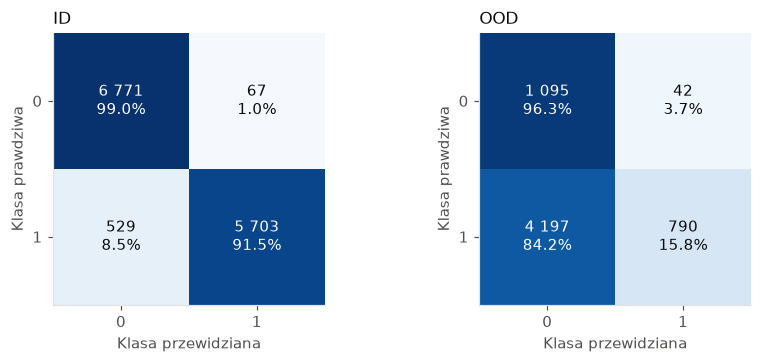

,przewidziane 0,przewidziane 1
prawdziwe 0,6771,67
prawdziwe 1,529,5703


,przewidziane 0,przewidziane 1
prawdziwe 0,1095,42
prawdziwe 1,4197,790


In [8]:
matrices = plot_confusion_matrices(corpus_sets, threshold, FIGURES / "confusion_matrices.pdf")
for name, matrix in matrices.items():
    matrix.to_csv(TABLES / f"confusion_matrix_{name.lower()}.csv")
    display(matrix)

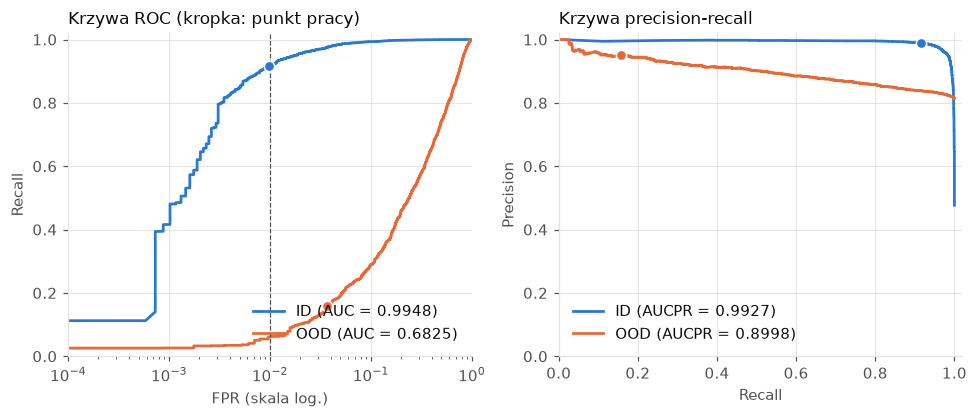

In [9]:
plot_curves(corpus_sets, threshold, FIGURES / "roc_pr_curves.pdf")